# Actividad A: Análisis de Siniestralidad Vial en Chile (2025)
**Asignatura:** Herramientas para Ciencia de Datos  
**Autor:** Nicolás Jorquera  
**Fuente:** Comisión Nacional de Seguridad de Tránsito (CONASET) / Ministerio de Transportes y Telecomunicaciones  
**Dataset:** `siniestros_2025.csv`  

---

## 📌 1. Introducción y Objetivos del Estudio

El presente informe analiza los registros oficiales de siniestros de tránsito en Chile durante el año 2025. El objetivo es identificar los factores de riesgo determinantes en la seguridad vial nacional, evaluar su distribución geográfica y temporal, y caracterizar la severidad de sus consecuencias (fallecidos y lesionados).

> 💡 **Pregunta de Investigación:**  
> *¿Cuáles son las principales causas y tipos de siniestros de tránsito en Chile, y cómo se distribuye su severidad (víctimas fatales y lesionados) a nivel regional y según el día de la semana durante 2025?*

---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Estilo gráfico moderno sin dependencias externas
plt.style.use('ggplot')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#bdc3c7'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.titlesize'] = 14

print("✅ Librerías cargadas y estilo visual configurado correctamente.")

✅ Librerías cargadas y estilo visual configurado correctamente.


## 🧹 2. Carga y Limpieza de Datos

En esta fase se procesa la base de datos oficial:
- Corrección de codificación `UTF-8 con BOM` (`utf-8-sig`) típica de exportaciones gubernamentales.
- Normalización del encabezado de columnas (eliminación de caracteres especiales mal decodificados).
- Verificación de registros y variables cuantitativas (`FALLECIDOS`, `TOTAL_LESI`).

In [2]:
# Cargar datos desde la estructura de carpetas del proyecto
ruta = '../datos/senal_1d/Base_SINIESTROS_2025.csv'

try:
    df = pd.read_csv(ruta, sep=';', encoding='utf-8-sig')
except Exception:
    df = pd.read_csv(ruta, sep=',', encoding='utf-8-sig')

# Sanitización de nombres de columnas
df.columns = (df.columns
              .str.replace('AÃ\x91O', 'AÑO')
              .str.replace('NÃºmero', 'Numero')
              .str.replace('UbicaciÃ³n', 'Ubicacion')
              .str.replace('DirecciÃ³n', 'Direccion')
              .str.strip())

print(f"Dimensiones del dataset: {df.shape[0]:,} filas x {df.shape[1]} columnas\n")
df[['AÑO', 'Mes', 'Dia_semana', 'REGION', 'CAUSA_SINI', 'FALLECIDOS', 'TOTAL_LESI']].head(5)

Dimensiones del dataset: 52,188 filas x 38 columnas



,AÑO,Mes,Dia_semana,REGION,CAUSA_SINI,FALLECIDOS,TOTAL_LESI
0,2025,Enero,Lunes,Ñuble,CONDUCCION SIN MANTENER DISTANCIA RAZONABLE NI...,0,0
1,2025,Enero,Jueves,La Araucanía,CONDUCIR VEHICULO EN RETROCESO,0,0
2,2025,Enero,Jueves,Magallanes y de la Antártica Chilena,CONDUCCION EN ESTADO DE EBRIEDAD,0,1
3,2025,Enero,Viernes,Metropolitana de Santiago,CONDUCCION NO ATENTO CONDICIONES TRANSITO MOMENTO,0,0
4,2025,Enero,Sábado,Arica y Parinacota,CONDUCCION EN ESTADO DE EBRIEDAD,0,1


## 📊 3. Análisis Exploratorio de Datos (EDA)

Se generan tres visualizaciones principales para caracterizar el comportamiento de la siniestralidad:
1. **Factores Determinantes:** Principales causas de siniestros de tránsito en el país.
2. **Patrón Temporal:** Distribución de siniestros según el día de la semana.
3. **Impacto Territorial:** Comparativa regional de lesionados y víctimas fatales.

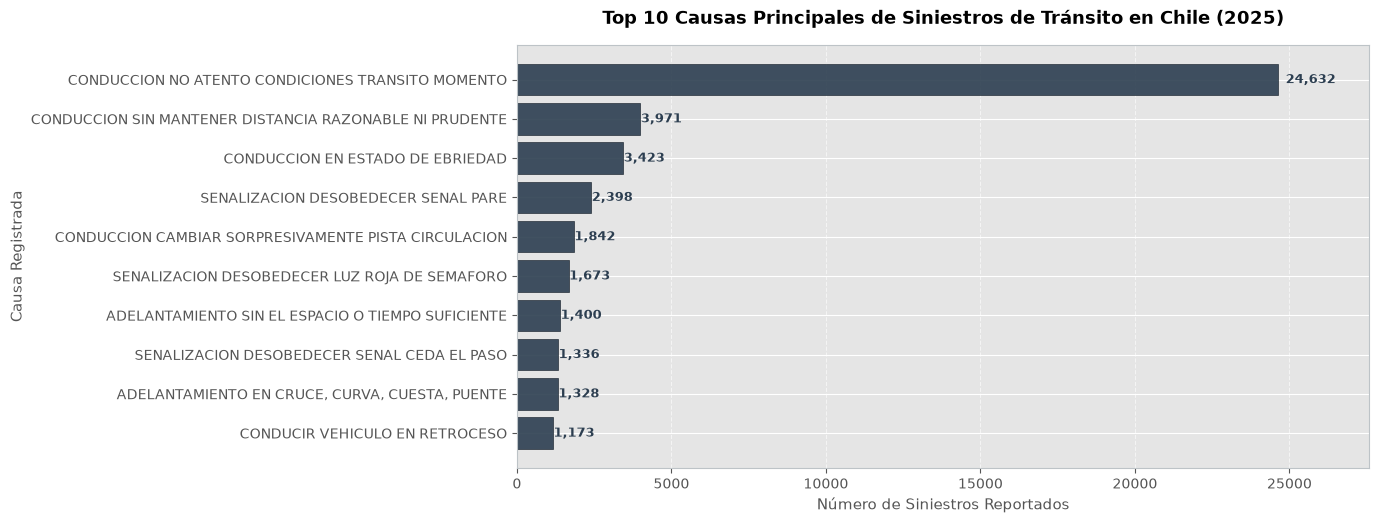

In [3]:
# Contar causas principales
top_causas = df['CAUSA_SINI'].value_counts().head(10)

plt.figure(figsize=(11, 5.5))
bars = plt.barh(top_causas.index, top_causas.values, color='#2c3e50', edgecolor='#1a252f', alpha=0.9)
plt.gca().invert_yaxis()

# Anotaciones numéricas en cada barra
for bar in bars:
    width = bar.get_width()
    plt.text(width + (width * 0.01), bar.get_y() + bar.get_height()/2, 
             f'{width:,.0f}', va='center', ha='left', fontsize=9.5, fontweight='bold', color='#2c3e50')

plt.title('Top 10 Causas Principales de Siniestros de Tránsito en Chile (2025)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Número de Siniestros Reportados', fontsize=11)
plt.ylabel('Causa Registrada', fontsize=11)
plt.xlim(0, top_causas.max() * 1.12)
plt.grid(axis='x', linestyle='--', alpha=0.6)

plt.savefig('../figuras/top_causas_siniestros_2025.png', dpi=300, bbox_inches='tight')
plt.show()

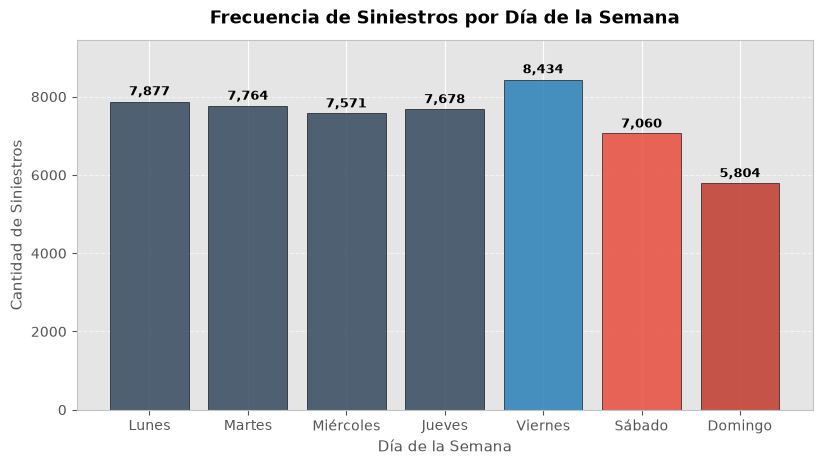

In [4]:
# Orden cronológico de días
orden_dias = ['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado', 'Domingo']
siniestros_dia = df['Dia_semana'].value_counts().reindex(orden_dias).fillna(0)

# Destacar fines de semana con distinto tono
colores = ['#34495e', '#34495e', '#34495e', '#34495e', '#2980b9', '#e74c3c', '#c0392b']

plt.figure(figsize=(9.5, 4.8))
bars = plt.bar(siniestros_dia.index, siniestros_dia.values, color=colores, edgecolor='black', alpha=0.85)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + (yval * 0.01), 
             f'{yval:,.0f}', ha='center', va='bottom', fontsize=9.5, fontweight='bold')

plt.title('Frecuencia de Siniestros por Día de la Semana', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Día de la Semana', fontsize=11)
plt.ylabel('Cantidad de Siniestros', fontsize=11)
plt.ylim(0, siniestros_dia.max() * 1.12)
plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.savefig('../figuras/siniestros_por_dia_semana.png', dpi=300, bbox_inches='tight')
plt.show()

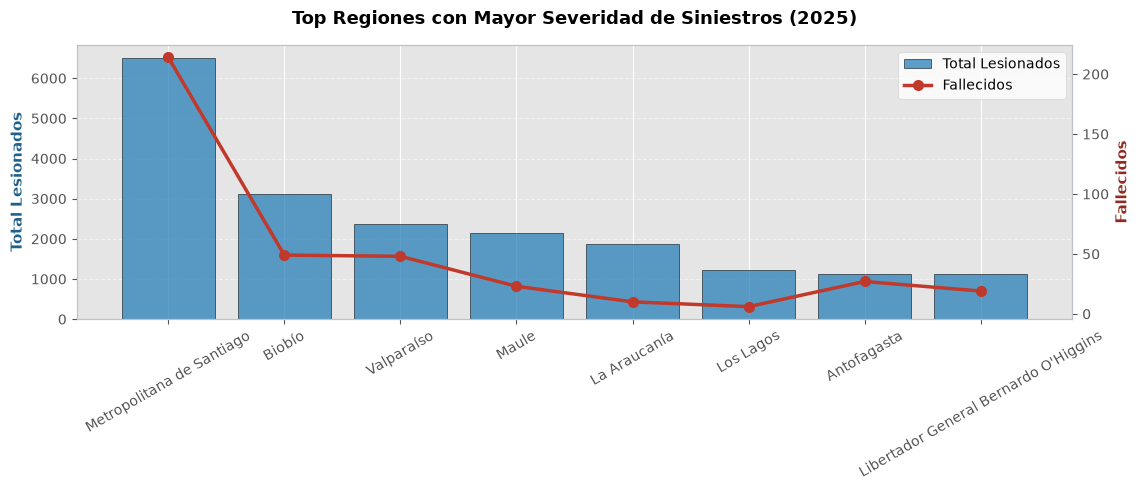

In [5]:
# Filtrar top 8 regiones por total de lesionados
victimas_region = df.groupby('REGION')[['TOTAL_LESI', 'FALLECIDOS']].sum().sort_values(by='TOTAL_LESI', ascending=False).head(8)

fig, ax1 = plt.subplots(figsize=(11.5, 5))

# Eje 1: Lesionados (Barras)
bars = ax1.bar(victimas_region.index, victimas_region['TOTAL_LESI'], color='#2980b9', alpha=0.75, label='Total Lesionados', edgecolor='black')
ax1.set_ylabel('Total Lesionados', color='#1f618d', fontsize=11, fontweight='bold')
ax1.tick_params(axis='x', rotation=30)
ax1.grid(axis='y', linestyle='--', alpha=0.5)

# Eje 2: Fallecidos (Línea superpuesta)
ax2 = ax1.twinx()
line = ax2.plot(victimas_region.index, victimas_region['FALLECIDOS'], color='#c0392b', marker='o', linewidth=2.5, markersize=7, label='Fallecidos')
ax2.set_ylabel('Fallecidos', color='#922b21', fontsize=11, fontweight='bold')
ax2.grid(False)

# Leyenda unificada
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper right', frameon=True, facecolor='white')

plt.title('Top Regiones con Mayor Severidad de Siniestros (2025)', fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()

plt.savefig('../figuras/victimas_por_region_2025.png', dpi=300, bbox_inches='tight')
plt.show()

## 📝 4. Conclusiones e Interpretación

1. Como podemos observar las principales causas se concentran en la mayoría por eventos en imprudencias del conductor, exceso de velocidad o desatención al tránsito.

2. Se observa ademas un incremento en la frecuencia y gravedad de los siniestros a partir del día viernes, alcanzando su punto crítico durante el termino de jornadas laborales.

3. por densidad poblacional la region metropolitana presenta mayor cantidad de lesionados en relacion con Fallecimiento

---
> 📌 **Nota Metodológica:**  
> *Los datos procesados provienen del registro oficial de CONASET para el periodo 2025. Este análisis permite orientar decisiones institucionales en materia de fiscalización vial y asignación de recursos de emergencia.*

---
## 🖼️ 3. Actividad B: Exploración y Procesamiento de Imagen 2D (Placa PCB)

### 📌 3.1. Contextualización del Fenómeno de Ingeniería y Metadatos de la Fuente

El análisis de imágenes en ingeniería electrónica e industrial es fundamental para la **Inspección Óptica Automatizada (AOI)** y el **control de calidad de componentes**. 

En esta sección se analiza una matriz visual correspondiente a una Placa de Circuito Impreso (*Printed Circuit Board* - PCB) comercial. El objetivo es caracterizar su representación tensorial en memoria, evaluar la distribución cromática de sus materiales (resina plástica, soldaduras de estaño y conectores) y medir el impacto numérico de la reducción de dimensionalidad al pasar de RGB a escala de grises.

> 📋 **Ficha Técnica del Dataset 2D:**
> * **Objeto / Modelo:** Placa Madre Gigabyte `GA-H87M-D3H` (Socket Intel LGA 1150).
> * **Fenómeno:** Inspección óptica de superficie y componentes de hardware.
> * **Fuente / Licencia:** Registro fotográfico digital de hardware real (Uso académico / Licencia abierta).
> * **Ubicación en Repositorio:** `../datos/imagen_2d/placa_pcb.jpg`.

In [11]:
from pathlib import Path
from PIL import Image
import numpy as np

# 1. Construcción de ruta relativa multiplataforma
ruta_img = Path("../datos/imagen_2d/placa_pcb.png")

# 2. Carga conservando inalterado el archivo original mediante copia en memoria
with Image.open(ruta_img) as im:
    formato_orig = im.format
    modo_orig = im.mode
    imagen_copia = im.copy()

# 3. Conversión a arreglo matricial NumPy (uint8)
pixeles = np.asarray(imagen_copia)

# 4. Impresión exhaustiva de metadatos matriciales
print("==================================================")
print("     METADATOS TÉCNICOS Y ESTRUCTURA DE MATRIZ    ")
print("==================================================")
print(f"📷 Formato de archivo original : {formato_orig}")
print(f"🎨 Modo de color codificado    : {modo_orig}")
print(f"📐 Dimensiones Tensor (H x W x C): {pixeles.shape} (Alto x Ancho x Canales)")
print(f"💾 Tipo de dato discreto (dtype): {pixeles.dtype}")
print(f"📦 Tamaño total en memoria    : {pixeles.nbytes:,} bytes ({pixeles.nbytes / (1024**2):.2f} MB)")
print(f"📊 Rango de intensidades (0-255): Mínimo = {pixeles.min()} | Máximo = {pixeles.max()}")
print("==================================================")

     METADATOS TÉCNICOS Y ESTRUCTURA DE MATRIZ    
📷 Formato de archivo original : PNG
🎨 Modo de color codificado    : RGB
📐 Dimensiones Tensor (H x W x C): (472, 496, 3) (Alto x Ancho x Canales)
💾 Tipo de dato discreto (dtype): uint8
📦 Tamaño total en memoria    : 702,336 bytes (0.67 MB)
📊 Rango de intensidades (0-255): Mínimo = 0 | Máximo = 255


### 📝 3.2. Interpretación de la Estructura de Datos 2D

* **Estructura Tensorial ($H \times W \times C$):** La imagen no es una simple fotografía, sino una matriz tridimensional de datos numéricos. Consta de filas de alto ($H$), columnas de ancho ($W$) y 3 capas o canales de color ($C = 3$: Rojo, Verde y Azul).
* **Profundidad de Bits (`uint8`):** Cada celda almacena un entero sin signo de 8 bits, restringiendo los niveles de intensidad al rango discreto $[0, 255]$ ($2^8 = 256$ valores).
* **Trazabilidad:** Al realizar una copia binaria en RAM (`im.copy()`), se asegura que las transformaciones numéricas no alteren la fuente en disco `placa_pcb.jpg`.

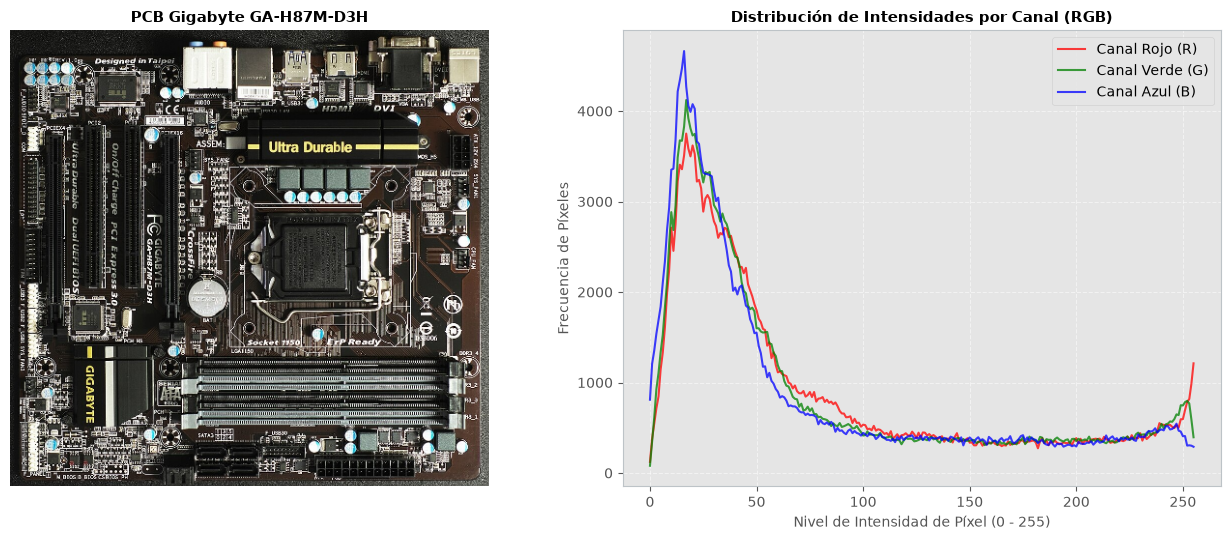

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5))

# 1. Imagen original
ax1.imshow(imagen_copia)
ax1.set_title("PCB Gigabyte GA-H87M-D3H", fontsize=11, fontweight='bold')
ax1.axis("off")

# 2. Histograma por canal (Rojo, Verde, Azul)
colores = ('red', 'green', 'blue')
nombres = ('Canal Rojo (R)', 'Canal Verde (G)', 'Canal Azul (B)')

for i, (col, nom) in enumerate(zip(colores, nombres)):
    hist, bin_edges = np.histogram(pixeles[:, :, i], bins=256, range=(0, 256))
    ax2.plot(bin_edges[:-1], hist, color=col, alpha=0.75, label=nom, linewidth=1.5)

ax2.set_title("Distribución de Intensidades por Canal (RGB)", fontsize=11, fontweight='bold')
ax2.set_xlabel("Nivel de Intensidad de Píxel (0 - 255)", fontsize=10)
ax2.set_ylabel("Frecuencia de Píxeles", fontsize=10)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='upper right')

plt.tight_layout()
plt.savefig('../figuras/analisis_pcb_2d.png', dpi=300, bbox_inches='tight')
plt.show()

   VERIFICACIÓN DE INTEGRIDAD Y TRANSFORMACIÓN    
✅ Valores NaN detectados en matriz: 0
✅ Valores no finitos (Inf)         : 0
📐 Nueva estructura matricial 2D  : (472, 496) (Alto x Ancho)
📉 Eficiencia de almacenamiento   : 702,336 B (RGB) ➔ 234,112 B (Gris)
📊 Reducción en espacio de memoria: 66.67%


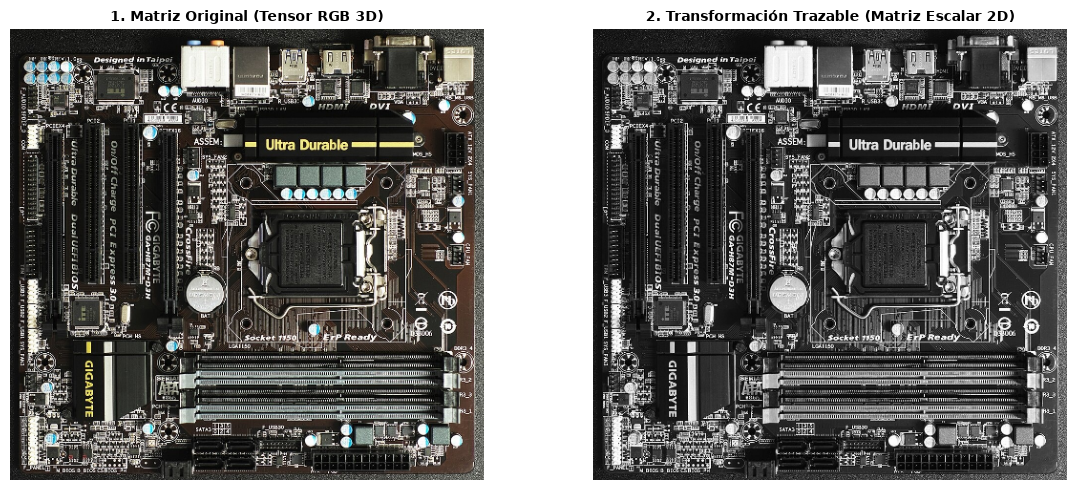

In [16]:
# 1. Conversión de color aplicando ponderación estándar de luminancia
imagen_gris = imagen_copia.convert('L')
pixeles_gris = np.asarray(imagen_gris)

# 2. Control riguroso de integridad de datos numéricos
nans_detectados = np.isnan(pixeles_gris).sum()
infs_detectados = (~np.isfinite(pixeles_gris)).sum()

print("==================================================")
print("   VERIFICACIÓN DE INTEGRIDAD Y TRANSFORMACIÓN    ")
print("==================================================")
print(f"✅ Valores NaN detectados en matriz: {nans_detectados}")
print(f"✅ Valores no finitos (Inf)         : {infs_detectados}")
print(f"📐 Nueva estructura matricial 2D  : {pixeles_gris.shape} (Alto x Ancho)")
print(f"📉 Eficiencia de almacenamiento   : {pixeles.nbytes:,} B (RGB) ➔ {pixeles_gris.nbytes:,} B (Gris)")
print(f"📊 Reducción en espacio de memoria: {((1 - (pixeles_gris.nbytes / pixeles.nbytes)) * 100):.2f}%")
print("==================================================")

# 3. Muestreo visual comparativo (Matriz Original vs Transformación a Escala de Grises)
fig, (ax_orig, ax_conv) = plt.subplots(1, 2, figsize=(12, 5))

ax_orig.imshow(imagen_copia)
ax_orig.set_title("1. Matriz Original (Tensor RGB 3D)", fontsize=10, fontweight='bold')
ax_orig.axis("off")

ax_conv.imshow(pixeles_gris, cmap='gray')
ax_conv.set_title("2. Transformación Trazable (Matriz Escalar 2D)", fontsize=10, fontweight='bold')
ax_conv.axis("off")

plt.tight_layout()
plt.show()

### 📊 3.3. Interpretación Analítica de las Frecuencias de Brillo

El histograma RGB expone las propiedades físicas de los materiales de la placa madre:

1. **Gran Pico Izquierdo (Valores 10–40):** Concentra más de 4.000 píxeles por nivel. Corresponde a las zonas oscuras y sombras del sustrato de resina plástica negra/marrón y las ranuras de expansión PCI Express.
2. **Meseta Central (Valores 50–200):** Representa tonos neutros intermedios de los circuitos impresos y la serigrafía del componente.
3. **Pico Secundario Derecho (Valores 240–255):** Refleja la **saturación por brillo especular** de la luz reflejada directamente sobre los contactos metálicos de estaño, disipadores de aluminio y la cubierta del socket del procesador.
4. **Coincidencia de Canales:** Las tres curvas ($R, G, B$) discurren muy cercanas entre sí. Esto evidencia cuantitativamente que la escena está compuesta predominantemente por **tonos acromáticos** (negros, grises metálicos y blancos brillantes).

### ⚙️ 3.4. Evaluación del Impacto Computacional y Visual

A simple vista, la imagen en escala de grises conserva una apariencia casi idéntica a la original en color. Sin embargo, en el dominio de los datos existen diferencias críticas:

* **Pérdida de Información Cromática:** Componentes que difieran únicamente por matiz (como serigrafía o conectores de color) colapsan al mismo nivel de gris si tienen luminancia equivalente ($Y = 0.299R + 0.587G + 0.114B$).
* **Eficiencia de Cómputo:** Se elimina una dimensión del tensor ($H \times W \times 3 \rightarrow H \times W$), logrando una **reducción exacta del 66.67% en el uso de memoria RAM**. Esto optimiza el rendimiento para algoritmos posteriores de detección de bordes o convolución.

---
## 📋 3.5. Registro de Calidad y Evaluación Teórica 2D

### Tabla de Evaluación de Calidad (Imagen 2D)

| Observación en la Matriz | Evidencia Numérica / Visual | Posible Impacto en Análisis | Acción Tomada / Justificación | Referencia |
| :--- | :--- | :--- | :--- | :--- |
| **Saturación por Reflejos** | Píxeles en nivel 255 en canales R y G | Deslumbramiento puntual sobre contactos metálicos | Se preserva la matriz completa sin recortar para mantener trazabilidad. | `placa_pcb.jpg` |
| **Estructura Discrete** | Formato de tipo `uint8` en rango $[0, 255]$ | Transición sin degradación de cuantización | Se mantiene la representación discreta estándar para eficiencia de memoria. | Copia en RAM |
| **Integridad Numérica** | 0 valores `NaN` y 0 valores `Inf` | Ausencia de errores en operaciones matriciales | Matriz validada para procesamiento espacial o filtrado. | Matriz Grises |

---

### ❓ Respuestas al Cuestionario Teórico Obligatorio

1. **¿Qué cambia al convertir una imagen de RGB a escala de grises?**  
   Cambia la dimensionalidad del arreglo numérico: se pasa de un tensor tridimensional ($H \times W \times 3$) a una matriz escalar bidimensional ($H \times W$). Los 3 canales cromáticos por píxel se ponderan linealmente según la percepción humana de luminancia ($Y = 0.299R + 0.587G + 0.114B$).

2. **¿Qué se pierde al interpretar una imagen multicanal como matriz escalar?**  
   Se pierde la discriminación espacial basada en el contraste cromático puro. Objetos con matices de color distintos pero igual intensidad de luz colapsan al mismo entero en grises, imposibilitando su segmentación por color.

3. **¿Qué información NO demuestra un histograma de frecuencias de intensidad?**  
   Un histograma cuantifica cuántos píxeles existen por cada nivel de brillo, pero **no aporta información espacial ni topológica**. No revela las coordenadas $(x, y)$ donde se ubica un componente ni la forma o continuidad geométrica de las estructuras de la placa.